# ASSIGNMENT 2: BÀI TOÁN PHÂN LOẠI ĐA LỚP TRÊN DỮ LIỆU THỜI TIẾT (OPEN-METEO)
## Triển khai mô hình Softmax Regression từ đầu bằng NumPy (Scratch)

In [21]:
# Import các thư viện tiêu chuẩn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Thiết lập đồ họa đồng nhất
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

## Bước 1: Khám phá Dữ liệu & Xử lý Đặc trưng (Data Preprocessing & Feature Engineering)


In [22]:
# 1. Đọc dữ liệu
df = pd.read_csv('weather_openmeteo.csv')
print(f"Tổng số mẫu dữ liệu: {len(df):,} dòng, {df.shape[1]} cột")

# 2. Trích xuất đặc trưng thời gian
df['Hour'] = df['Time'].apply(lambda t: int(str(t).split(':')[0]))
df['Date_dt'] = pd.to_datetime(df['Date'], errors='coerce')
df['Month'] = df['Date_dt'].dt.month

print("\nThống kê các giá trị thời tiết nguyên bản:")
print(df['Weather'].value_counts())

Tổng số mẫu dữ liệu: 51,120 dòng, 7 cột

Thống kê các giá trị thời tiết nguyên bản:
Weather
Overcast            22197
Light drizzle        9031
Clear sky            5911
Mainly clear         4484
Partly cloudy        4066
Moderate drizzle     1831
Moderate rain        1389
Slight rain          1325
Dense drizzle         613
Heavy rain            273
Name: count, dtype: int64


## Bước 2: Định nghĩa Nhãn Đa Lớp (Multi-Class Label Encoding)

Để bài toán có ý nghĩa khí tượng học và cân bằng dữ liệu, chúng ta phân loại thời tiết thành **4 nhóm chính**:
- **Lớp 0 - Clear / Fair (Trời trong / Ít mây)**: `Clear sky`, `Mainly clear`
- **Lớp 1 - Cloudy / Overcast (Nhiều mây / Âm u)**: `Partly cloudy`, `Overcast`
- **Lớp 2 - Drizzle (Mưa phùn)**: `Light drizzle`, `Moderate drizzle`, `Dense drizzle`
- **Lớp 3 - Rain (Mưa rào / Mưa to)**: `Slight rain`, `Moderate rain`, `Heavy rain`

In [23]:
# Hàm ánh xạ nhãn đa lớp
def map_weather_to_class(weather_str):
    if weather_str in ['Clear sky', 'Mainly clear']:
        return 0
    elif weather_str in ['Partly cloudy', 'Overcast']:
        return 1
    elif weather_str in ['Light drizzle', 'Moderate drizzle', 'Dense drizzle']:
        return 2
    elif weather_str in ['Slight rain', 'Moderate rain', 'Heavy rain']:
        return 3
    return -1

df['Target_Multi'] = df['Weather'].apply(map_weather_to_class)

class_names = {
    0: 'Clear / Fair (Trời trong)',
    1: 'Cloudy / Overcast (Mây / Âm u)',
    2: 'Drizzle (Mưa phùn)',
    3: 'Rain (Mưa rào / Mưa lớn)'
}

summary_df = pd.DataFrame({
    'Tên nhóm thời tiết': [class_names[c] for c in sorted(class_names.keys())],
    'Số lượng mẫu': df['Target_Multi'].value_counts().sort_index().values,
    'Tỷ lệ (%)': (df['Target_Multi'].value_counts(normalize=True).sort_index().values * 100).round(2)
})
print("Phân phối 4 lớp mục tiêu trong tập dữ liệu:")
display(summary_df)

Phân phối 4 lớp mục tiêu trong tập dữ liệu:


,Tên nhóm thời tiết,Số lượng mẫu,Tỷ lệ (%)
0,Clear / Fair (Trời trong),10395,20.33
1,Cloudy / Overcast (Mây / Âm u),26263,51.38
2,Drizzle (Mưa phùn),11475,22.45
3,Rain (Mưa rào / Mưa lớn),2987,5.84


## Bước 3: Phân chia Train/Test, Chuẩn hóa Đặc trưng & Mã hóa One-Hot


In [24]:
feature_cols = ['Temperature', 'Humidity', 'Wind', 'Barometer', 'Hour', 'Month']
X = df[feature_cols].values
y = df['Target_Multi'].values
n_classes = len(np.unique(y))

# Phân chia 80% Train, 20% Test ngẫu nhiên
np.random.seed(42)
indices = np.random.permutation(len(X))
train_size = int(0.8 * len(X))

train_idx = indices[:train_size]
test_idx = indices[train_size:]

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

# Chuẩn hóa Z-score thuần NumPy
mean_train = np.mean(X_train, axis=0)
std_train = np.std(X_train, axis=0)
std_train = np.where(std_train == 0, 1e-8, std_train)

X_train_scaled = (X_train - mean_train) / std_train
X_test_scaled = (X_test - mean_train) / std_train

# Thêm hệ số chặn (Bias term x0 = 1)
X_train_b = np.c_[np.ones(len(X_train_scaled)), X_train_scaled]
X_test_b = np.c_[np.ones(len(X_test_scaled)), X_test_scaled]

# Hàm mã hóa One-Hot thuần NumPy
def to_one_hot(y_labels, num_classes):
    return np.eye(num_classes)[y_labels]

Y_train_one_hot = to_one_hot(y_train, n_classes)
Y_test_one_hot = to_one_hot(y_test, n_classes)

print(f"Kích thước ma trận Train X: {X_train_b.shape} (đã gồm 1 cột bias)")
print(f"Kích thước ma trận Test X : {X_test_b.shape} (đã gồm 1 cột bias)")
print(f"Kích thước ma trận Train Y (One-hot): {Y_train_one_hot.shape}")
print(f"Kích thước ma trận Test Y (One-hot) : {Y_test_one_hot.shape}")

Kích thước ma trận Train X: (40896, 7) (đã gồm 1 cột bias)
Kích thước ma trận Test X : (10224, 7) (đã gồm 1 cột bias)
Kích thước ma trận Train Y (One-hot): (40896, 4)
Kích thước ma trận Test Y (One-hot) : (10224, 4)


## Bước 4: Xây dựng Mô hình Softmax Regression từ đầu bằng NumPy (Scratch)


In [25]:
class SoftmaxRegressionNumPy:
    """
    Mô hình Softmax Regression (Multinomial Logistic Regression)
    được lập trình thuần NumPy, tối ưu hóa bằng Gradient Descent.
    """
    def __init__(self, learning_rate=0.2, n_iterations=1000, verbose=True):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.verbose = verbose
        self.weights = None  # Ma trận kích thước (n_features, n_classes)
        self.loss_history = []

    def _softmax(self, Z):
        # Trừ giá trị lớn nhất trên mỗi hàng để tránh tràn số (Overflow)
        exp_Z = np.exp(Z - np.max(Z, axis=1, keepdims=True))
        return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

    def _compute_loss(self, Y_true, Y_pred, eps=1e-15):
        # Giới hạn giá trị xác suất để tránh log(0)
        Y_pred_clipped = np.clip(Y_pred, eps, 1.0 - eps)
        # Tính Cross-Entropy trung bình trên N mẫu
        loss = -np.mean(np.sum(Y_true * np.log(Y_pred_clipped), axis=1))
        return loss

    def fit(self, X, Y_one_hot):
        n_samples, n_features = X.shape
        n_classes = Y_one_hot.shape[1]
        
        # Khởi tạo ma trận trọng số ban đầu bằng 0
        self.weights = np.zeros((n_features, n_classes))
        self.loss_history = []

        for i in range(self.n_iterations):
            # 1. Forward pass: Tính logits và phân phối xác suất Softmax
            Z = np.dot(X, self.weights)
            Y_pred = self._softmax(Z)

            # 2. Tính giá trị hàm mất mát Categorical Cross-Entropy
            loss = self._compute_loss(Y_one_hot, Y_pred)
            self.loss_history.append(loss)

            # 3. Tính Gradient theo công thức: (1/N) * X^T (Y_pred - Y_true)
            gradient = (1.0 / n_samples) * np.dot(X.T, (Y_pred - Y_one_hot))

            # 4. Cập nhật ma trận trọng số W
            self.weights -= self.learning_rate * gradient

            # Theo dõi tiến trình huấn luyện
            if self.verbose and (i % 100 == 0 or i == self.n_iterations - 1):
                print(f"Vòng lặp {i:4d}/{self.n_iterations} | Loss: {loss:.6f}")

        return self

    def predict_proba(self, X):
        Z = np.dot(X, self.weights)
        return self._softmax(Z)

    def predict(self, X):
        # Chọn lớp có xác suất dự đoán lớn nhất (Argmax)
        probabilities = self.predict_proba(X)
        return np.argmax(probabilities, axis=1)

## Bước 5: Huấn luyện Mô hình & Trực quan hóa Đường cong Mất mát (Loss Curve)

Bắt đầu huấn luyện mô hình Softmax Regression (NumPy Scratch)...
Vòng lặp    0/1000 | Loss: 1.386294
Vòng lặp  100/1000 | Loss: 1.038364
Vòng lặp  200/1000 | Loss: 1.028226
Vòng lặp  300/1000 | Loss: 1.025057
Vòng lặp  400/1000 | Loss: 1.023777
Vòng lặp  500/1000 | Loss: 1.023175
Vòng lặp  600/1000 | Loss: 1.022853
Vòng lặp  700/1000 | Loss: 1.022659
Vòng lặp  800/1000 | Loss: 1.022532
Vòng lặp  900/1000 | Loss: 1.022441
Vòng lặp  999/1000 | Loss: 1.022374


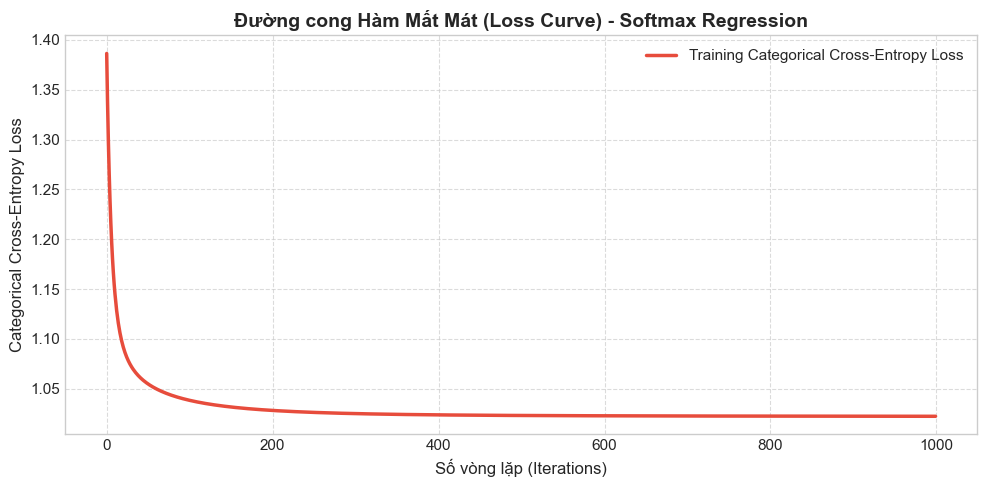

In [26]:
print("Bắt đầu huấn luyện mô hình Softmax Regression (NumPy Scratch)...")
softmax_model = SoftmaxRegressionNumPy(learning_rate=0.3, n_iterations=1000, verbose=True)
softmax_model.fit(X_train_b, Y_train_one_hot)

# Vẽ đồ thị Loss qua các epochs
plt.figure(figsize=(10, 5))
plt.plot(softmax_model.loss_history, color='#e74c3c', linewidth=2.5, label='Training Categorical Cross-Entropy Loss')
plt.title('Đường cong Hàm Mất Mát (Loss Curve) - Softmax Regression', fontsize=14, fontweight='bold')
plt.xlabel('Số vòng lặp (Iterations)', fontsize=12)
plt.ylabel('Categorical Cross-Entropy Loss', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

## Bước 6: Đánh giá Mô hình Đa lớp Toàn diện (NumPy Scratch)

KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH SOFTMAX REGRESSION (NUMPY SCRATCH)
* Overall Accuracy (Độ chính xác tổng): 53.11%
* Macro F1-Score                       : 0.3131
* Weighted F1-Score                    : 0.4556
---------------------------------------------------------------


,Lớp,Tên lớp,Precision (%),Recall (%),F1-Score,Số mẫu (Support)
0,0,Clear / Fair (Trời trong),41.05,5.47,0.0965,2140
1,1,Cloudy / Overcast (Mây / Âm u),55.67,86.80,0.6784,5304
2,2,Drizzle (Mưa phùn),43.16,30.31,0.3561,2197
3,3,Rain (Mưa rào / Mưa lớn),34.13,7.38,0.1213,583


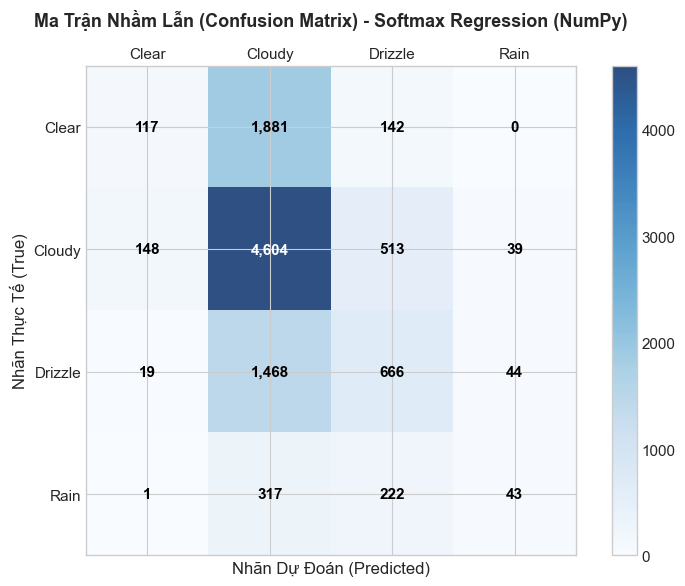

In [27]:
# Dự đoán trên tập kiểm tra Test
y_test_pred = softmax_model.predict(X_test_b)

# 1. Tính Ma trận nhầm lẫn Confusion Matrix thuần NumPy
conf_mat = np.zeros((n_classes, n_classes), dtype=int)
for true_label, pred_label in zip(y_test, y_test_pred):
    conf_mat[true_label, pred_label] += 1

# 2. Tính Precision, Recall, F1 theo từng lớp
class_metrics = []
total_samples = len(y_test)

for c in range(n_classes):
    tp = conf_mat[c, c]
    fp = np.sum(conf_mat[:, c]) - tp
    fn = np.sum(conf_mat[c, :]) - tp
    support = np.sum(conf_mat[c, :])
    
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    
    class_metrics.append({
        'Lớp': c,
        'Tên lớp': class_names[c],
        'Precision (%)': round(precision * 100, 2),
        'Recall (%)': round(recall * 100, 2),
        'F1-Score': round(f1, 4),
        'Số mẫu (Support)': support
    })

df_metrics = pd.DataFrame(class_metrics)
overall_accuracy = np.trace(conf_mat) / total_samples

# Tính Macro và Weighted average
macro_f1 = df_metrics['F1-Score'].mean()
weighted_f1 = np.sum(df_metrics['F1-Score'] * df_metrics['Số mẫu (Support)']) / total_samples

print("===============================================================")
print("KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH SOFTMAX REGRESSION (NUMPY SCRATCH)")
print("===============================================================")
print(f"* Overall Accuracy (Độ chính xác tổng): {overall_accuracy * 100:.2f}%")
print(f"* Macro F1-Score                       : {macro_f1:.4f}")
print(f"* Weighted F1-Score                    : {weighted_f1:.4f}")
print("---------------------------------------------------------------")
display(df_metrics)

# 3. Vẽ biểu đồ Heatmap Confusion Matrix bằng Matplotlib
fig, ax = plt.subplots(figsize=(8, 6))
cax = ax.matshow(conf_mat, cmap='Blues', alpha=0.85)
fig.colorbar(cax)

labels = ['Clear', 'Cloudy', 'Drizzle', 'Rain']
ax.set_xticks(range(n_classes))
ax.set_yticks(range(n_classes))
ax.set_xticklabels(labels, fontsize=11)
ax.set_yticklabels(labels, fontsize=11)

for i in range(n_classes):
    for j in range(n_classes):
        val = conf_mat[i, j]
        ax.text(j, i, f"{val:,}", ha='center', va='center', 
                color='white' if val > conf_mat.max() / 2 else 'black', 
                fontsize=11, fontweight='bold')

plt.title('Ma Trận Nhầm Lẫn (Confusion Matrix) - Softmax Regression (NumPy)', fontsize=13, pad=15, fontweight='bold')
plt.xlabel('Nhãn Dự Đoán (Predicted)', fontsize=12)
plt.ylabel('Nhãn Thực Tế (True)', fontsize=12)
plt.tight_layout()
plt.show()